# Objectively Reviewed: data preparation and NLP analysis

This notebook runs the complete data preparation workflow and initial NLP analysis in one place. It
combines [data cleaning](notebooks/data_cleaning.ipynb),
[HTML extraction](notebooks/extract_html_data.ipynb), and
[data/text merging](notebooks/merge_data_and_text.ipynb), in that order.
The three original notebooks remain available and unchanged.

The goal is to pair cleaned album metadata and audio features with the correct
Pitchfork review text, keep an audit trail for data preparation, and test
whether review language predicts Pitchfork scores and Spotify audio features.

| Stage | Input | What happens | Main output |
| --- | --- | --- | --- |
| 1. Clean metadata | `data.csv` | Normalize text, handle missing values, check audio features, and validate records | `outputs/data_clean.csv` |
| 2. Extract reviews | `pitchfork-scrape/raw-html/` | Parse saved HTML, identify reviews, exclude duplicate groups, and build the text dataset | `outputs/review_text.csv` |
| 3. Merge | Both generated CSVs and the extraction exclusion report | Match artist, album, and date; require author and score agreement | `outputs/full_review.csv` |
| 4. NLP baseline | `outputs/full_review.csv` | Fit TF-IDF/Ridge models and compare with a training-mean baseline | Held-out metrics and selected word coefficients |

## How to run

1. Open this notebook in VS Code or Jupyter and select a Python 3 kernel with
   **NumPy**, **pandas**, and **scikit-learn** installed. The repository's
   `requirements.txt` lists the dependencies; extraction and merging use the
   standard library. The reusable NLP model implementation is in
   `scripts/preliminary_results.py`.
2. Review the paths and cleaning settings in **0. Setup and configuration**.
   The default inputs are the repository's existing CSV and saved HTML files;
   no download or API credentials are required.
3. Restart the kernel and choose **Run All**. Run from top to bottom so each
   stage can use the files and helpers created earlier. HTML extraction over
   the complete collection can take several minutes.
4. The final section reads the generated `outputs/full_review.csv`, fits the
   NLP baselines, and reports held-out results. Review the audit reports under
   `outputs/` before interpreting them.

Paths are anchored to the detected repository root, so this notebook works
with a kernel started in the root, `notebooks/`, or a deeper repository
directory. If the kernel starts elsewhere, set `REPO_ROOT_OVERRIDE` below.
Changing `OUTPUTS_DIR` in the configuration redirects every stage together.

Runs regenerate the CSVs and reports. Before replacing extracted text files,
the extraction stage archives the previous text directory under
`outputs/previous_text_reviews_*/text_reviews/`. The source CSV, saved HTML,
and original notebooks are preserved. After changing settings, restart the
kernel and rerun the full workflow.


## 0. Setup and configuration

Import the dependencies once, then define the paths used by all three stages.
Repository discovery searches the current working directory and its parents
for `data.csv` and `notebooks/`; it does not depend on the notebook being inside
`notebooks/`. No working-directory change is needed.


In [1]:
from pathlib import Path
import sys
import unicodedata

from IPython.display import display
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_extraction.text import CountVectorizer

In [2]:
# Usually leave this as None. Set an absolute repository path if the kernel
# starts outside this repository, for example Path("/path/to/objectively-reviewed").
REPO_ROOT_OVERRIDE = None

if REPO_ROOT_OVERRIDE is None:
    working_dir = Path.cwd().resolve()
    REPO_ROOT = next(
        (path for path in (working_dir, *working_dir.parents)
         if (path / "data.csv").is_file() and (path / "notebooks").is_dir()),
        None,
    )
else:
    REPO_ROOT = Path(REPO_ROOT_OVERRIDE).expanduser().resolve()

if REPO_ROOT is None:
    raise FileNotFoundError(
        "Could not locate the repository. Start the kernel inside the repository "
        "or set REPO_ROOT_OVERRIDE to its absolute path."
    )

# Edit paths here; all stages share these settings.
RAW_DATA_CSV = REPO_ROOT / "data.csv"
HTML_INPUTS = [REPO_ROOT / "pitchfork-scrape" / "raw-html"]
OUTPUTS_DIR = REPO_ROOT / "outputs"

CLEANING_OUTPUT_DIR = OUTPUTS_DIR / "data_cleaning"
DATA_CLEAN_CSV = OUTPUTS_DIR / "data_clean.csv"
EXTRACTION_DIR = OUTPUTS_DIR / "extracting_text"
TEXT_OUTPUT_DIR = OUTPUTS_DIR / "text_reviews"
REVIEW_TEXT_CSV = OUTPUTS_DIR / "review_text.csv"
DISCARDED_HTML_CSV = EXTRACTION_DIR / "discarded_html.csv"
FULL_REVIEW_CSV = OUTPUTS_DIR / "full_review.csv"

if not RAW_DATA_CSV.is_file():
    raise FileNotFoundError(f"Source CSV does not exist: {RAW_DATA_CSV}")
if not HTML_INPUTS or any(not Path(path).exists() for path in HTML_INPUTS):
    raise FileNotFoundError(f"Check the HTML input paths: {HTML_INPUTS}")

OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)
CLEANING_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Repository:", REPO_ROOT)
print("Source CSV:", RAW_DATA_CSV)
print("HTML inputs:", HTML_INPUTS)
print("Output directory:", OUTPUTS_DIR)


Repository: /home/ai4covid/test_stuff_2
Source CSV: /home/ai4covid/test_stuff_2/data.csv
HTML inputs: [PosixPath('/home/ai4covid/test_stuff_2/pitchfork-scrape/raw-html')]
Output directory: /home/ai4covid/test_stuff_2/outputs


### Cleaning choices and audit log

These are the defaults from the original cleaning notebook. In particular,
`SUSPECT_FEATURES_ACTION = "drop"` removes every row whose complete audio
feature vector is shared with a different artist; use `"flag"` to retain those
values or `"nan"` to retain the rows with blank audio features. The categorical
musical `key` column is dropped because its album averages are not meaningful.

Missing genres and labels remain missing by default. Release/review conflicts
are flagged, and a review more than two years after release is marked as a
reissue or retrospective. Each cleaning action records its affected count.


In [3]:
# ---- Settings ----------------------------------------------------------------
# Strings that really mean "missing" in text columns (compared case-insensitively)
MISSING_PLACEHOLDERS = ["none", "n/a", "na", "null", "nan", "-", "--", "?", "unknown", ""]

# Replace curly quotes/apostrophes with straight ones in names and titles.
# Makes joins with other sources (e.g. full review text) far more reliable.
NORMALIZE_QUOTES = True

# Drop rows where a key identifying field (artist or album) is missing
DROP_MISSING_KEY_FIELDS = True

# The 'key' column is an album average of a categorical value (0 = C, 1 = C#, ...),
# so it has no musical meaning. True drops it.
DROP_KEY_COLUMN = True

# What to do with rows whose audio features are identical to a different artist's
# album (likely a bad title-only match to Spotify):
#   "flag" -> keep values, add features_suspect = True
#   "nan"  -> flag AND blank the audio features
#   "drop" -> remove the rows entirely
SUSPECT_FEATURES_ACTION = "drop"

# Years between release and review after which a review is treated as a reissue/retrospective
REISSUE_GAP_YEARS = 2

# Fill missing genre / record label with "Unknown" (False keeps them as blank/NaN)
FILL_UNKNOWN_CATEGORIES = False

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

# ---- Cleaning log ------------------------------------------------------------
cleaning_log = []

def log(step, detail, affected):
    """Record one cleaning action and print it."""
    cleaning_log.append({"step": step, "detail": detail, "affected": int(affected)})
    print(f"[{step}] {detail}: {int(affected):,}")


## 1. Clean the metadata and audio features

This stage starts from `data.csv` on every full run and produces validated
metadata for the later join. `source_row` preserves the zero-based source
record position, while `review_id` identifies rows within this cleaned export.
Neither ID is the URL-derived `source_id` created during HTML extraction.


### 1.1 Read and verify the source file

Read the bytes, try UTF-8, and fall back to Latin-1 if decoding fails. Report
the encoding, byte-order mark, physical line count, and parsed dimensions.
Work on a copy and attach `source_row` before any records are removed.


In [4]:
with open(RAW_DATA_CSV, "rb") as f:
    raw_bytes = f.read()

# Encoding check: fails loudly if the file is not valid UTF-8
try:
    raw_text = raw_bytes.decode("utf-8")
    encoding = "utf-8"
except UnicodeDecodeError:
    raw_text = raw_bytes.decode("latin-1")
    encoding = "latin-1"
print("Encoding:", encoding)
print("Has BOM:", raw_text.startswith("\ufeff"))

line_count = raw_text.count("\n") + (0 if raw_text.endswith("\n") else 1)

alb_data_raw = pd.read_csv(RAW_DATA_CSV, encoding=encoding)
print(f"Lines in file: {line_count:,}  |  Rows parsed: {len(alb_data_raw):,}  |  Columns: {alb_data_raw.shape[1]}")

if line_count - 1 == len(alb_data_raw):
    print("OK: one row per line, no embedded line breaks.")
else:
    print("WARNING: row count differs from line count. Inspect quoted fields with line breaks.")

alb_data = alb_data_raw.copy()
alb_data.insert(0, "source_row", np.arange(len(alb_data)))   # keeps a link back to the raw file
ROWS_AT_START = len(alb_data)


Encoding: utf-8
Has BOM: False
Lines in file: 18,404  |  Rows parsed: 18,403  |  Columns: 18
OK: one row per line, no embedded line breaks.


### 1.2 Profile the raw data

Preview the records, inspect data types, missingness, and distinct values,
and summarize numeric distributions. Define the text and audio-feature
columns used by the checks below; the unit-interval features should lie in
`[0, 1]`.


In [5]:
print("Shape:", alb_data.shape)
display(alb_data.head())


Shape: (18403, 19)


,source_row,artist,album,reviewauthor,score,releaseyear,reviewdate,recordlabel,genre,danceability,energy,key,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,0,Studio 1,Studio 1,Andy Battaglia,8.5,2009.0,February 18 2009,Studio,Electronic,0.511917,0.499667,5.250000,-5.626583,0.031983,0.724917,0.024493,0.165367,0.555083,101.395167
1,1,John Fahey,The Great Santa Barbara Oil Slick,Mark Richardson,8.2,2005.0,February 13 2005,Water,Folk/Country,0.369765,0.325412,4.470588,-19.153824,0.148624,0.647053,0.559133,0.527782,0.179465,107.622647
2,2,Reigning Sound,Too Much Guitar,Stephen M. Deusner,8.3,2004.0,August 19 2004,In the Red,Electronic,0.253943,0.912857,4.428571,-1.089500,0.055500,0.000253,0.751214,0.199071,0.552786,133.895500
3,3,The Red Thread,After the Last,Chris Dahlen,7.3,2003.0,July 17 2003,Badman,Rock,0.425400,0.433474,5.700000,-12.871000,0.028260,0.310325,0.224137,0.125150,0.451400,104.354200
4,4,Mac Miller,Swimming,Evan Rytlewski,7.5,2018.0,August 3 2018,Warner Bros.,Rap,0.624846,0.438154,4.153846,-9.456077,0.170246,0.652462,0.012819,0.121131,0.281138,122.121308


In [6]:
profile = pd.DataFrame({
    "dtype": alb_data.dtypes.astype(str),
    "missing": alb_data.isna().sum(),
    "missing_%": (alb_data.isna().mean() * 100).round(2),
    "unique": alb_data.nunique(),
})
profile


,dtype,missing,missing_%,unique
source_row,int64,0,0.00,18403
artist,object,1,0.01,9049
album,object,0,0.00,17714
reviewauthor,object,0,0.00,564
score,float64,0,0.00,100
releaseyear,float64,325,1.77,61
reviewdate,object,0,0.00,4957
recordlabel,object,26,0.14,3286
genre,object,1289,7.00,10
danceability,float64,0,0.00,12407


In [7]:
alb_data.describe().T


,count,mean,std,min,25%,50%,75%,max
source_row,18403.0,9201.000000,5312.632838,0.00000,4600.500000,9201.000000,13801.500000,18402.000
score,18403.0,7.033255,1.251850,0.00000,6.500000,7.300000,7.800000,10.000
releaseyear,18078.0,2009.315411,7.708710,1957.00000,2005.000000,2010.000000,2015.000000,2019.000
danceability,18403.0,0.510635,0.159833,-1.00000,0.405784,0.510417,0.622000,0.974
energy,18403.0,0.600806,0.204257,-1.00000,0.471787,0.624364,0.750586,0.999
key,18403.0,5.215836,1.619708,-1.00000,4.333333,5.230769,6.100000,11.000
loudness,18403.0,-9.318390,4.264038,-51.72875,-11.248350,-8.492333,-6.416397,4.078
speechiness,18403.0,0.091125,0.092428,-1.00000,0.040704,0.056808,0.100029,0.958
acousticness,18403.0,0.302895,0.263730,-1.00000,0.089842,0.229806,0.463416,0.996
instrumentalness,18403.0,0.278616,0.300740,-1.00000,0.010060,0.153433,0.506816,0.982


In [8]:
TEXT_COLS = ["artist", "album", "reviewauthor", "recordlabel", "genre"]
FEATURE_COLS = ["danceability", "energy", "key", "loudness", "speechiness",
                "acousticness", "instrumentalness", "liveness", "valence", "tempo"]
UNIT_INTERVAL_COLS = ["danceability", "energy", "speechiness", "acousticness",
                      "instrumentalness", "liveness", "valence"]   # should lie in [0, 1]


### 1.3 Remove exact duplicate records

Compare every original data column, excluding the tracking column
`source_row`. Display duplicate groups and retain the first identical record.
Later stages handle repeated review identities separately because rows can
share a review key while differing in another field, such as record label.


In [9]:
data_cols = [c for c in alb_data.columns if c != "source_row"]
dup_mask = alb_data.duplicated(subset=data_cols, keep="first")
display(alb_data[alb_data.duplicated(subset=data_cols, keep=False)][["source_row", "artist", "album", "reviewauthor", "reviewdate"]])
alb_data = alb_data[~dup_mask].copy()
log("Duplicates", "Exact duplicate rows removed", dup_mask.sum())


,source_row,artist,album,reviewauthor,reviewdate
8012,8012,Fiona Apple,When the Pawn...,Judy Berman,March 24 2019
8013,8013,Fiona Apple,When the Pawn...,Judy Berman,March 24 2019
12874,12874,Stick Men with Ray Guns,Some People Deserve to Suffer,Andy Beta,March 5 2003
12875,12875,Stick Men with Ray Guns,Some People Deserve to Suffer,Andy Beta,March 5 2003


[Duplicates] Exact duplicate rows removed: 2


### 1.4 Normalize text formatting

Normalize Unicode, optionally straighten quotes, replace non-breaking
spaces, and collapse repeated whitespace in names, titles, authors, labels,
and genres. Log how many values change in each column. The cleaning quote
map has its own name so it remains independent of the later matching rules.


In [10]:
CLEANING_QUOTE_MAP = str.maketrans({"\u201c": '"', "\u201d": '"', "\u2018": "'", "\u2019": "'",
                           "\u00a0": " "})   # also replaces non-breaking spaces

def normalize_text(s):
    if pd.isna(s):
        return s
    s = unicodedata.normalize("NFC", str(s))
    if NORMALIZE_QUOTES:
        s = s.translate(CLEANING_QUOTE_MAP)
    return " ".join(s.split())    # trims and collapses all runs of whitespace

for col in TEXT_COLS:
    before_unique = alb_data[col].nunique()
    new = alb_data[col].map(normalize_text)
    changed = (new.fillna("<NA>") != alb_data[col].fillna("<NA>")).sum()
    alb_data[col] = new
    log("Text normalisation", f"{col}: values changed ({before_unique:,} -> {alb_data[col].nunique():,} unique)", changed)


[Text normalisation] artist: values changed (9,049 -> 9,047 unique): 140
[Text normalisation] album: values changed (17,714 -> 17,711 unique): 150
[Text normalisation] reviewauthor: values changed (564 -> 559 unique): 83
[Text normalisation] recordlabel: values changed (3,286 -> 3,283 unique): 41
[Text normalisation] genre: values changed (10 -> 10 unique): 0


### 1.5 Convert placeholder strings to missing values

Treat case-insensitive entries such as `unknown`, `n/a`, and `--` as missing
according to `MISSING_PLACEHOLDERS`. Report their frequency and replace them
with `NaN`, allowing missing-value checks to detect them consistently.


In [11]:
placeholders = {p.lower() for p in MISSING_PLACEHOLDERS}

for col in TEXT_COLS:
    mask = alb_data[col].notna() & alb_data[col].str.lower().isin(placeholders)
    if mask.any():
        print(f"{col}: placeholder values found -> {alb_data.loc[mask, col].value_counts().to_dict()}")
    alb_data.loc[mask, col] = np.nan
    log("Disguised missing", f"{col}: placeholder strings -> NaN", mask.sum())


[Disguised missing] artist: placeholder strings -> NaN: 0
[Disguised missing] album: placeholder strings -> NaN: 0
[Disguised missing] reviewauthor: placeholder strings -> NaN: 0
recordlabel: placeholder values found -> {'none': 607, 'Unknown': 7}
[Disguised missing] recordlabel: placeholder strings -> NaN: 614
genre: placeholder values found -> {'none': 11}
[Disguised missing] genre: placeholder strings -> NaN: 11


### 1.6 Unify capitalization variants

For artists, authors, labels, and genres, group case-insensitive variants
and use the most frequent spelling in each group. Album titles keep their
capitalization; this step does not guess corrections for distinct names.


In [12]:
def unify_case_variants(series):
    s = series.dropna()
    counts = s.value_counts()
    canonical = (counts.rename_axis("value").reset_index()
                       .assign(key=lambda d: d["value"].str.casefold())
                       .sort_values(["key", "count"], ascending=[True, False])
                       .drop_duplicates("key")
                       .set_index("key")["value"])
    groups = s.groupby(s.str.casefold()).agg(lambda x: sorted(set(x)))
    variants = groups[groups.str.len() > 1]
    return series.map(lambda v: canonical[v.casefold()] if pd.notna(v) else v), variants

for col in ["artist", "reviewauthor", "recordlabel", "genre"]:
    new, variants = unify_case_variants(alb_data[col])
    changed = (new.fillna("<NA>") != alb_data[col].fillna("<NA>")).sum()
    if len(variants):
        print(f"\n{col}: {len(variants)} case-variant groups, e.g. {variants.head(5).tolist()}")
    alb_data[col] = new
    log("Case variants", f"{col}: values unified to most common spelling", changed)



artist: 3 case-variant groups, e.g. [['Billy Woods', 'billy woods'], ['The Comet Is Coming', 'The Comet is Coming'], ['WIVES', 'Wives']]
[Case variants] artist: values unified to most common spelling: 3
[Case variants] reviewauthor: values unified to most common spelling: 0

recordlabel: 2 case-variant groups, e.g. [['GOOD', 'Good'], ['ITALIANS DO IT BETTER', 'Italians Do It Better']]
[Case variants] recordlabel: values unified to most common spelling: 3
[Case variants] genre: values unified to most common spelling: 0


### 1.7 Convert dates and release years

Parse review dates in the source's month/day/year format and report failures.
Verify that nonmissing release years are integers, then store them using
pandas' nullable integer type. Optionally fill missing genres and labels with
`Unknown` if the corresponding setting is enabled.


In [13]:
parsed = pd.to_datetime(alb_data["reviewdate"], format="%B %d %Y", errors="coerce")
unparsed = parsed.isna() & alb_data["reviewdate"].notna()
if unparsed.any():
    print("Dates that could not be parsed:", alb_data.loc[unparsed, "reviewdate"].head().tolist())
alb_data["reviewdate"] = parsed
log("Types", "reviewdate parsed to datetime (failures)", unparsed.sum())

non_integer_years = (alb_data["releaseyear"].dropna() % 1 != 0).sum()
assert non_integer_years == 0, "releaseyear has non-integer values"
alb_data["releaseyear"] = alb_data["releaseyear"].astype("Int64")
log("Types", "releaseyear converted to nullable integer (missing values)", alb_data["releaseyear"].isna().sum())

for col in ["genre", "recordlabel"]:
    if FILL_UNKNOWN_CATEGORIES:
        n = alb_data[col].isna().sum()
        alb_data[col] = alb_data[col].fillna("Unknown")
        log("Types", f"{col}: missing filled with 'Unknown'", n)

print(alb_data[["reviewdate", "releaseyear"]].dtypes)


[Types] reviewdate parsed to datetime (failures): 0
[Types] releaseyear converted to nullable integer (missing values): 325
reviewdate     datetime64[ns]
releaseyear             Int64
dtype: object


### 1.8 Handle missing artist or album

Display rows without the fields needed to identify an album. With the
default settings, remove those rows and record the count; the configuration
can instead keep them for inspection.


In [14]:
key_missing = alb_data["artist"].isna() | alb_data["album"].isna()
display(alb_data.loc[key_missing, ["source_row", "artist", "album", "reviewauthor", "reviewdate"]])
if DROP_MISSING_KEY_FIELDS:
    alb_data = alb_data[~key_missing].copy()
    log("Missing keys", "Rows dropped (missing artist or album)", key_missing.sum())
else:
    log("Missing keys", "Rows with missing artist or album (kept)", key_missing.sum())


,source_row,artist,album,reviewauthor,reviewdate
4720,4720,NaN,Cellar EP,Kevin Lozano,2016-02-29


[Missing keys] Rows dropped (missing artist or album): 1


### 1.9 Validate audio-feature values

Replace the `-1` missing-value sentinel with `NaN` and blank invalid values
in features restricted to `[0, 1]`. Flag positive loudness and tempo outside
50–250 BPM for inspection. Drop the averaged `key` column when configured,
and update the feature list used by subsequent checks.


In [15]:
sentinel_any = (alb_data[FEATURE_COLS] == -1).any(axis=1)
sentinel_all = (alb_data[FEATURE_COLS] == -1).all(axis=1)
print(f"Rows with -1 in all features: {sentinel_all.sum()}, in only some: {(sentinel_any & ~sentinel_all).sum()}")
alb_data[FEATURE_COLS] = alb_data[FEATURE_COLS].mask(alb_data[FEATURE_COLS] == -1)
log("Audio features", "Rows with -1 sentinel values set to NaN", sentinel_any.sum())

# Out-of-range values: a negative album average usually means one track carried the -1
# sentinel and was averaged in, so the value is contaminated and can't be trusted.
oor = (alb_data[UNIT_INTERVAL_COLS] < 0) | (alb_data[UNIT_INTERVAL_COLS] > 1)
print("\nValues outside [0, 1] after sentinel removal:\n", oor.sum().to_string())
if oor.any().any():
    display(alb_data.loc[oor.any(axis=1), ["artist", "album"] + UNIT_INTERVAL_COLS])
alb_data[UNIT_INTERVAL_COLS] = alb_data[UNIT_INTERVAL_COLS].mask(oor)
log("Audio features", "Out-of-range [0, 1] feature values set to NaN", oor.sum().sum())

alb_data["loudness_positive"] = alb_data["loudness"] > 0
alb_data["tempo_unusual"] = (alb_data["tempo"] < 50) | (alb_data["tempo"] > 250)
log("Audio features", "Rows flagged with positive loudness", alb_data["loudness_positive"].sum())
log("Audio features", "Rows flagged with unusual tempo (<50 or >250 BPM)", alb_data["tempo_unusual"].sum())

if DROP_KEY_COLUMN:
    non_int = (alb_data["key"].dropna() % 1 != 0).sum()
    print(f"\n'key' is non-integer (averaged) in {non_int:,} rows -> dropping column")
    alb_data = alb_data.drop(columns="key")
    FEATURE_COLS = [c for c in FEATURE_COLS if c != "key"]
    log("Audio features", "'key' column dropped (rows with averaged values)", non_int)


Rows with -1 in all features: 8, in only some: 0
[Audio features] Rows with -1 sentinel values set to NaN: 8

Values outside [0, 1] after sentinel removal:
 danceability        0
energy              0
speechiness         1
acousticness        0
instrumentalness    1
liveness            0
valence             0


,artist,album,danceability,energy,speechiness,acousticness,instrumentalness,liveness,valence
12570,Rahim,Ideal Lives,0.518364,0.531909,-0.058236,0.012756,-0.085783,0.075236,0.462364


[Audio features] Out-of-range [0, 1] feature values set to NaN: 2
[Audio features] Rows flagged with positive loudness: 9
[Audio features] Rows flagged with unusual tempo (<50 or >250 BPM): 5

'key' is non-integer (averaged) in 15,089 rows -> dropping column
[Audio features] 'key' column dropped (rows with averaged values): 15,089


### 1.10 Handle suspected wrong Spotify matches

Find complete feature vectors that are identical across different artists
after rounding to six decimal places. These can indicate a title-only match
to the wrong Spotify album, and the file does not identify which row is
correct. Flag every member of each group, then apply
`SUSPECT_FEATURES_ACTION` (`drop` by default).


In [16]:
has_features = alb_data[FEATURE_COLS].notna().all(axis=1)
feat_key = alb_data.loc[has_features, FEATURE_COLS].round(6).astype(str).agg("|".join, axis=1)
artists_per_vector = alb_data.loc[has_features].groupby(feat_key)["artist"].transform("nunique")

alb_data["features_suspect"] = False
alb_data.loc[artists_per_vector.index, "features_suspect"] = artists_per_vector > 1

examples = (alb_data[alb_data["features_suspect"]]
            .assign(_k=feat_key)
            .sort_values(["_k", "artist"])
            [["artist", "album", "energy", "tempo"]]
            .head(10))
display(examples)
log("Suspect features", "Rows sharing identical features with a different artist", alb_data["features_suspect"].sum())

if SUSPECT_FEATURES_ACTION == "nan":
    alb_data.loc[alb_data["features_suspect"], FEATURE_COLS] = np.nan
    log("Suspect features", "Suspect rows: audio features set to NaN", alb_data["features_suspect"].sum())
elif SUSPECT_FEATURES_ACTION == "drop":
    n = alb_data["features_suspect"].sum()
    alb_data = alb_data[~alb_data["features_suspect"]].copy()
    log("Suspect features", "Suspect rows dropped", n)


,artist,album,energy,tempo
4397,Muse,Drones,0.027630,81.425000
4398,Nico Muhly,Drones,0.027630,81.425000
12635,Nosaj Thing,Drift,0.079600,153.779000
12636,The Men,Drift,0.079600,153.779000
1506,Kath Bloom,Thin Thin Line,0.111600,82.949818
1505,Trans Am,The Red Line,0.111600,82.949818
6464,Hepcat,Out of Nowhere,0.637000,200.085000
6463,Jimi Tenor,Out of Nowhere,0.637000,200.085000
7870,Carmen Villain,Sleeper,0.123675,115.411750
7871,Ty Segall,Sleeper,0.123675,115.411750


[Suspect features] Rows sharing identical features with a different artist: 1,589
[Suspect features] Suspect rows dropped: 1,589


### 1.11 Check release year against review date

Calculate `years_since_release`. Mark gaps greater than
`REISSUE_GAP_YEARS` with `is_reissue`, and negative gaps with
`release_after_review`. Keep these rows with their flags rather than
changing their dates or scores.


In [17]:
review_year = alb_data["reviewdate"].dt.year
gap = (review_year - alb_data["releaseyear"]).astype("Int64")
alb_data["years_since_release"] = gap

alb_data["is_reissue"] = (gap > REISSUE_GAP_YEARS).fillna(False).astype(bool)
alb_data["release_after_review"] = (gap < 0).fillna(False).astype(bool)

log("Cross-field", f"Reviews flagged as reissue (> {REISSUE_GAP_YEARS} years after release)", alb_data["is_reissue"].sum())
log("Cross-field", "Rows where release year is after review year (flagged)", alb_data["release_after_review"].sum())
display(alb_data.loc[alb_data["release_after_review"], ["artist", "album", "releaseyear", "reviewdate"]].head())


[Cross-field] Reviews flagged as reissue (> 2 years after release): 786
[Cross-field] Rows where release year is after review year (flagged): 24


,artist,album,releaseyear,reviewdate
124,The Avalanches,Since I Left You,2001,1999-12-31
532,Love Is All,Nine Times That Same Song,2006,2005-12-05
1215,Abilene,Abilene,2001,2000-12-31
3685,Cave In,Jupiter,2001,2000-08-08
4647,Alpha,The Impossible Thrill,2001,2000-12-31


### 1.12 Identify repeat reviews across dates

Group albums by case-insensitive artist and album, then order each group by
review date. Add a review count and sequence number. Reviews on different
dates remain eligible, allowing an original review and a later retrospective
to be distinguished during merging.


In [18]:
album_key = alb_data["artist"].str.casefold() + " || " + alb_data["album"].str.casefold()
alb_data = alb_data.assign(_album_key=album_key).sort_values(["_album_key", "reviewdate"])
alb_data["album_review_count"] = alb_data.groupby("_album_key")["_album_key"].transform("size")
alb_data["album_review_number"] = alb_data.groupby("_album_key").cumcount() + 1
alb_data = alb_data.drop(columns="_album_key").sort_values("source_row")

repeats = alb_data[alb_data["album_review_count"] > 1]
log("Repeat reviews", "Rows belonging to albums reviewed more than once (kept)", len(repeats))
display(repeats[["artist", "album", "reviewauthor", "score", "reviewdate", "is_reissue"]].head(8))


[Repeat reviews] Rows belonging to albums reviewed more than once (kept): 88


,artist,album,reviewauthor,score,reviewdate,is_reissue
12,American Football,American Football,Ian Cohen,8.6,2014-05-21,True
13,American Football,American Football,Ian Cohen,7.7,2016-10-26,False
99,Crystal Castles,Crystal Castles,Ian Cohen,7.8,2008-03-17,False
100,Crystal Castles,Crystal Castles,Ian Cohen,8.5,2010-04-29,False
321,Ty Segall,Ty Segall,Stuart Berman,8.0,2017-01-25,False
322,Ty Segall,Ty Segall,Stephen M. Deusner,6.7,2009-07-17,False
399,Atmosphere,God Loves Ugly,Nate Patrin,6.6,2009-02-20,True
400,Atmosphere,God Loves Ugly,Sam Chennault,5.7,2002-07-04,False


### 1.13 Assign review IDs and arrange columns

Restore source order, assign sequential `review_id` values, and place
identity fields, audio features, helper columns, and flags in a predictable
order. `source_row` remains available for tracing a row to `data.csv`.


In [19]:
alb_data = alb_data.sort_values("source_row").reset_index(drop=True)
alb_data.insert(0, "review_id", np.arange(1, len(alb_data) + 1))

flag_cols = ["is_reissue", "release_after_review", "features_suspect",
             "loudness_positive", "tempo_unusual"]
helper_cols = ["years_since_release", "album_review_count", "album_review_number"]
core_cols = ["review_id", "source_row", "artist", "album", "reviewauthor", "score",
             "releaseyear", "reviewdate", "recordlabel", "genre"]
alb_data = alb_data[core_cols + FEATURE_COLS + helper_cols + flag_cols]
alb_data.head()


,review_id,source_row,artist,album,reviewauthor,score,releaseyear,reviewdate,recordlabel,genre,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,years_since_release,album_review_count,album_review_number,is_reissue,release_after_review,features_suspect,loudness_positive,tempo_unusual
0,1,0,Studio 1,Studio 1,Andy Battaglia,8.5,2009,2009-02-18,Studio,Electronic,0.511917,0.499667,-5.626583,0.031983,0.724917,0.024493,0.165367,0.555083,101.395167,0,1,1,False,False,False,False,False
1,2,1,John Fahey,The Great Santa Barbara Oil Slick,Mark Richardson,8.2,2005,2005-02-13,Water,Folk/Country,0.369765,0.325412,-19.153824,0.148624,0.647053,0.559133,0.527782,0.179465,107.622647,0,1,1,False,False,False,False,False
2,3,2,Reigning Sound,Too Much Guitar,Stephen M. Deusner,8.3,2004,2004-08-19,In the Red,Electronic,0.253943,0.912857,-1.089500,0.055500,0.000253,0.751214,0.199071,0.552786,133.895500,0,1,1,False,False,False,False,False
3,4,3,The Red Thread,After the Last,Chris Dahlen,7.3,2003,2003-07-17,Badman,Rock,0.425400,0.433474,-12.871000,0.028260,0.310325,0.224137,0.125150,0.451400,104.354200,0,1,1,False,False,False,False,False
4,5,6,Jessica Lea Mayfield,With Blasphemy So Heartfelt,Stephen M. Deusner,8.2,2008,2008-11-11,Polymer,Rock,0.447583,0.399083,-8.402000,0.032267,0.694750,0.004033,0.123142,0.237933,111.549917,0,1,1,False,False,False,False,False


### 1.14 Validate the cleaned dataset

Stop execution if IDs are duplicated, exact duplicates remain, scores or
feature values violate their allowed ranges, dates fail to parse, or text
still contains whitespace and missing-placeholder problems. Show the final
data types and missingness after the assertions pass.


In [20]:
assert alb_data["review_id"].is_unique, "review_id is not unique"
assert not alb_data.drop(columns=["review_id", "source_row"]).duplicated().any(), "Exact duplicates remain"
assert alb_data["score"].between(0, 10).all(), "Score outside 0-10"
assert alb_data["reviewdate"].notna().all(), "Unparsed review dates"
assert alb_data["releaseyear"].dropna().between(1900, alb_data["reviewdate"].dt.year.max() + 1).all(), "Implausible release year"
assert (alb_data[FEATURE_COLS] != -1).all().all(), "Sentinel -1 values remain"
assert ((alb_data[UNIT_INTERVAL_COLS] >= 0) & (alb_data[UNIT_INTERVAL_COLS] <= 1) | alb_data[UNIT_INTERVAL_COLS].isna()).all().all(), "Features outside [0, 1]"
for col in ["artist", "album", "reviewauthor", "recordlabel", "genre"]:
    s = alb_data[col].dropna()
    assert (s == s.str.strip()).all(), f"{col}: leading/trailing whitespace remains"
    assert not s.str.contains("  ").any(), f"{col}: double spaces remain"
    assert not s.str.lower().isin({p.lower() for p in MISSING_PLACEHOLDERS}).any(), f"{col}: placeholder strings remain"
if DROP_MISSING_KEY_FIELDS:
    assert alb_data[["artist", "album"]].notna().all().all(), "Missing artist/album remain"
print("All validation checks passed.")


All validation checks passed.


In [21]:
pd.DataFrame({
    "dtype": alb_data.dtypes.astype(str),
    "missing": alb_data.isna().sum(),
    "missing_%": (alb_data.isna().mean() * 100).round(2),
})


,dtype,missing,missing_%
review_id,int64,0,0.00
source_row,int64,0,0.00
artist,object,0,0.00
album,object,0,0.00
reviewauthor,object,0,0.00
score,float64,0,0.00
releaseyear,Int64,301,1.79
reviewdate,datetime64[ns],0,0.00
recordlabel,object,575,3.42
genre,object,1192,7.09


### 1.15 Export the cleaned metadata and log

Write `outputs/data_cleaning/log_df.csv` with one record per cleaning action.
Save `outputs/data_clean.csv` as UTF-8 with ISO-formatted review dates, then
read it back to verify the row count and ID uniqueness. The next stage builds
the review-text dataset from the saved HTML.


In [22]:
log_df = pd.DataFrame(cleaning_log)
log_df.to_csv(CLEANING_OUTPUT_DIR / "log_df.csv", index=False, encoding="utf-8")
print(f"Rows: {ROWS_AT_START:,} -> {len(alb_data):,}  ({ROWS_AT_START - len(alb_data):,} removed)")
log_df


Rows: 18,403 -> 16,811  (1,592 removed)


,step,detail,affected
0,Duplicates,Exact duplicate rows removed,2
1,Text normalisation,"artist: values changed (9,049 -> 9,047 unique)",140
2,Text normalisation,"album: values changed (17,714 -> 17,711 unique)",150
3,Text normalisation,reviewauthor: values changed (564 -> 559 unique),83
4,Text normalisation,"recordlabel: values changed (3,286 -> 3,283 un...",41
5,Text normalisation,genre: values changed (10 -> 10 unique),0
6,Disguised missing,artist: placeholder strings -> NaN,0
7,Disguised missing,album: placeholder strings -> NaN,0
8,Disguised missing,reviewauthor: placeholder strings -> NaN,0
9,Disguised missing,recordlabel: placeholder strings -> NaN,614


In [23]:
alb_data.to_csv(DATA_CLEAN_CSV, index=False, encoding="utf-8", date_format="%Y-%m-%d")

check = pd.read_csv(DATA_CLEAN_CSV, parse_dates=["reviewdate"])
assert len(check) == len(alb_data), "Row count changed on round-trip"
assert check["review_id"].is_unique
print(f"Saved {len(check):,} rows x {check.shape[1]} columns to {DATA_CLEAN_CSV}")


Saved 16,811 rows x 27 columns to /home/ai4covid/test_stuff_2/outputs/data_clean.csv


## 2. Extract review text from the saved HTML

Read the saved pages in `HTML_INPUTS`, identify each review from its canonical
URL, and build `review_text.csv`. Each retained page also gets a text file and
a manifest entry linking it to its source HTML.

The reusable implementation lives in [html_to_txt.py](scripts/html_to_txt.py),
[txt_to_csv.py](scripts/txt_to_csv.py), and
[review_common.py](scripts/review_common.py). The cells below show the main
steps and their results; parsing, validation, and file-writing helpers stay in
those scripts.


In [24]:
scripts_dir = str(REPO_ROOT / "scripts")
if scripts_dir not in sys.path:
    sys.path.insert(0, scripts_dir)

from html_to_txt import find_html_files, parse_html_files, write_outputs
from txt_to_csv import build_review_csv
from review_common import IDENTITY_FIELDS


### 2.1 Find HTML inputs and parse reviews

Read the first artist link and album heading, publication date and author from
JSON-LD, the first score, the meta description, and the review paragraphs.
Names and punctuation are preserved. A canonical URL (without tracking
parameters or fragments) determines the stable 32-character `source_id`.

Parsing prints progress every 2,000 files and records invalid pages in the
skipped log. This step leaves existing output files in place.


In [25]:
files = find_html_files(HTML_INPUTS)
print(f"Found {len(files):,} HTML files.")

records, skipped = parse_html_files(files)
print(f"Parsed {len(records):,} reviews; skipped {len(skipped):,} source files.")
display(pd.DataFrame(records, columns=IDENTITY_FIELDS).head(3))


Found 21,321 HTML files.


Skipping 11617-partie-t.html: no review paragraphs found in a div.contents container


Parsed 2000/21321 HTML files.
Parsed 4000/21321 HTML files.


Skipping 1391-being-ridden.html: no review paragraphs found in a div.contents container


Parsed 6000/21321 HTML files.


Skipping 16697-record.html: no nonempty album field found in the review heading


... (2 outputs left out)

Parsed 18000/21321 HTML files.


Skipping 9464-shine-on.html: no review paragraphs found in a div.contents container


Parsed 20000/21321 HTML files.
Parsed 21,316 reviews; skipped 5 source files.


,source_id,artist,album,reviewdate,reviewauthor,score
0,c7af38b5e299e7cdece3756934c1e947,Liars,TFCF,2017-08-28,Patric Fallon,7.5
1,03b726ca0a9b1a25d770fb7a42cdebfc,E-40,Connected and Respected,2018-04-14,Torii MacAdams,6.7
2,22cf35b500b7ee65b2b0f2f9988a748b,Sublime,40oz. to Freedom,2018-02-25,Evan Rytlewski,5.6


### 2.2 Exclude duplicate groups and save text files

Discard every member of a repeated source-ID or normalized artist/album/date
group. Normalization handles Unicode, quotes, whitespace, and case without
removing punctuation or changing the saved names.

Stage the retained text files, archive the previous text directory, and write
the manifest and exclusion reports under `extracting_text/`. Pages without
descriptions retain their text files and are listed in
`missing_descriptions.txt`.


In [26]:
converted, discarded, backup = write_outputs(
    records, skipped, TEXT_OUTPUT_DIR, EXTRACTION_DIR
)
print(f"Wrote {converted:,} text files; discarded {discarded:,} duplicate HTML files.")
if backup is not None:
    print("Previous text files archived in:", backup)
print("Manifest and extraction reports:", EXTRACTION_DIR)


Wrote 21,312 text files; discarded 4 duplicate HTML files.
Manifest and extraction reports: /home/ai4covid/test_stuff_2/outputs/extracting_text


### 2.3 Build the review CSV and inspect the extraction

Read identity fields from the manifest. Exclude files listed as missing a
description, then split each remaining file at its first blank line into the
description and review body. Validate every input before replacing
`review_text.csv`.

The summary accounts for parsed, skipped, duplicate, and missing-description
cases. The preview shows the identity fields and text available for merging.


In [27]:
csv_rows, missing_description_count = build_review_csv(
    input_dir=TEXT_OUTPUT_DIR,
    manifest_path=EXTRACTION_DIR / "html_text_match.csv",
    missing_descriptions_path=EXTRACTION_DIR / "missing_descriptions.txt",
    output_path=REVIEW_TEXT_CSV,
)

extraction_summary = pd.Series({
    "HTML inputs": len(files),
    "Invalid pages skipped": len(skipped),
    "Duplicate HTML files discarded": discarded,
    "Text files retained": converted,
    "Reviews excluded without descriptions": missing_description_count,
    "Review CSV rows": len(csv_rows),
}, name="count").rename_axis("extraction")
display(extraction_summary.to_frame())
display(pd.DataFrame(csv_rows).head(3))
print("Saved:", REVIEW_TEXT_CSV)


,count
extraction,
HTML inputs,21321
Invalid pages skipped,5
Duplicate HTML files discarded,4
Text files retained,21312
Reviews excluded without descriptions,41
Review CSV rows,21271


,source_id,artist,album,reviewdate,reviewauthor,score,description,review
0,c7af38b5e299e7cdece3756934c1e947,Liars,TFCF,2017-08-28,Patric Fallon,7.5,"Now working solo, Liars’ Angus Andrew looks ba...","To follow Liars’ long, prolific, often paradox..."
1,03b726ca0a9b1a25d770fb7a42cdebfc,E-40,Connected and Respected,2018-04-14,Torii MacAdams,6.7,E-40 sounds like a resigned elder statesman on...,"According to Plutarch, Alexander the Great wep..."
2,22cf35b500b7ee65b2b0f2f9988a748b,Sublime,40oz. to Freedom,2018-02-25,Evan Rytlewski,5.6,The debut album from the SoCal trio is a flawe...,Most Sublime fans have only ever known Bradley...


Saved: /home/ai4covid/test_stuff_2/outputs/review_text.csv


## 3. Merge cleaned metadata and review text

Match the generated CSVs on normalized artist, album, and publication date.
Accept a link only when one candidate exists and its author and numeric score
agree (`8` and `8.0` compare equally). Each accepted `source_id` appears once.
The output preserves the cleaned metadata values.

[merge_reviews.py](scripts/merge_reviews.py) contains the matching, exclusion,
validation, and audit-report implementation. The notebook keeps the rules,
the merge call, and the results visible.


### 3.1 Apply exclusions and merge validated matches

- Discard every metadata row in a repeated artist/album/date group, together
  with corresponding text rows and the duplicate HTML groups from section 2.
- Retain the explicit exclusion of Prince's December 2, 2019 review of `1999`;
  the April 30, 2016 review remains eligible.
- Discard repeated source IDs. Keep invalid fields, ambiguous candidates, and
  date, author, or score conflicts unresolved, with a reason for each row.

The merge writes `full_review.csv` and the four audit CSVs in
`missed_on_merge/` and `discarded_on_merge/`. It also verifies that every input
row is accounted for as matched, unresolved, or discarded.


In [28]:
from merge_reviews import merge_reviews

stats = merge_reviews(
    data_path=DATA_CLEAN_CSV,
    text_path=REVIEW_TEXT_CSV,
    output_dir=OUTPUTS_DIR,
    discarded_html_path=DISCARDED_HTML_CSV,
    output_path=FULL_REVIEW_CSV,
)
print(f"Accepted {stats['merged']:,} unique review links.")
print(f"Repeated metadata groups: {stats['duplicate_metadata_groups']:,}")


Accepted 16,222 unique review links.
Repeated metadata groups: 6


### 3.2 Compare merge outcomes

Each accepted link uses one metadata row and one review-text row. The table
and stacked bars show how much of each input was matched, left unresolved, or
discarded.


,Matched,Unresolved,Discarded
input,,,
Cleaned metadata,16222,575,14
Review text,16222,5043,6


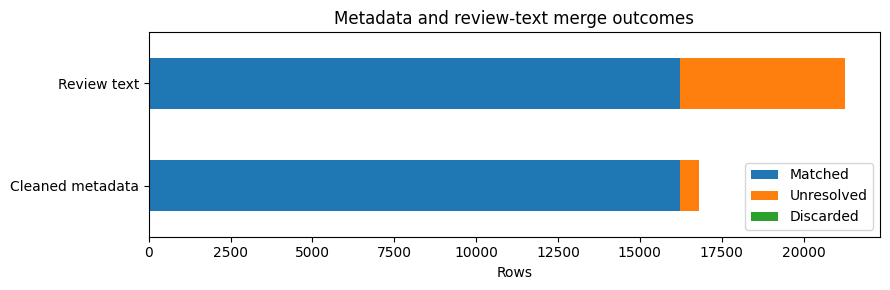

In [29]:
merge_counts = pd.DataFrame({
    "Matched": [stats["merged"], stats["merged"]],
    "Unresolved": [stats["data_unmatched"], stats["text_unmatched"]],
    "Discarded": [stats["data_discarded"], stats["text_discarded"]],
}, index=pd.Index(["Cleaned metadata", "Review text"], name="input"))
display(merge_counts)

merge_counts.plot.barh(stacked=True, figsize=(9, 3))
plt.xlabel("Rows")
plt.ylabel("")
plt.title("Metadata and review-text merge outcomes")
plt.tight_layout()
plt.show()


### 3.3 Review exclusion reasons and audit paths

Inspect why metadata rows were left unresolved or discarded before using the
matched subset for analysis. The audit CSVs retain the original input columns
and add `merge_reason` or `discard_reason`; they also include the corresponding
review-text outcomes.


In [30]:
print("Unresolved metadata reasons:")
display(pd.Series(stats["data_unmatched_reasons"], dtype="int64", name="rows")
        .rename_axis("merge_reason").to_frame())
print("Discarded metadata reasons:")
display(pd.Series(stats["data_discard_reasons"], dtype="int64", name="rows")
        .rename_axis("discard_reason").to_frame())

print("Merged CSV:", FULL_REVIEW_CSV)
print("Unresolved rows:", OUTPUTS_DIR / "missed_on_merge")
print("Discarded rows:", OUTPUTS_DIR / "discarded_on_merge")


Unresolved metadata reasons:


,rows
merge_reason,
no_matching_review,575


Discarded metadata reasons:


,rows
discard_reason,
duplicate_metadata_key,12
duplicate_html_review,2


Merged CSV: /home/ai4covid/test_stuff_2/outputs/full_review.csv
Unresolved rows: /home/ai4covid/test_stuff_2/outputs/missed_on_merge
Discarded rows: /home/ai4covid/test_stuff_2/outputs/discarded_on_merge


### 3.4 Inspect accepted review links

The original metadata values are retained. `source_id` links each accepted
row to `review_text.csv`, the extraction manifest, and its text file. Preview
the identities and a short excerpt to check what reaches the analysis.


In [31]:
merged_preview = pd.read_csv(FULL_REVIEW_CSV, dtype={"source_id": "string"}, nrows=5)
display(merged_preview[IDENTITY_FIELDS])
display(merged_preview[["artist", "album", "description", "review"]].head(1)
        .assign(review=lambda frame: frame["review"].str.slice(0, 300)))


,source_id,artist,album,reviewdate,reviewauthor,score
0,37ab31b68172e82813f2a369f582cbaa,Studio 1,Studio 1,2009-02-18,Andy Battaglia,8.5
1,262b7d646d70d63ae9dda3963574311e,John Fahey,The Great Santa Barbara Oil Slick,2005-02-13,Mark Richardson,8.2
2,63d7991eedbf90992723439b6b87ff0b,Reigning Sound,Too Much Guitar,2004-08-19,Stephen M. Deusner,8.3
3,ece0303b76fc865d6d8429b558fd8680,The Red Thread,After the Last,2003-07-17,Chris Dahlen,7.3
4,e7a2b5ec09d43c300f2ba9381e1b06fe,Jessica Lea Mayfield,With Blasphemy So Heartfelt,2008-11-11,Stephen M. Deusner,8.2


,artist,album,description,review
0,Studio 1,Studio 1,A collection of early techno tracks by German ...,Wolfgang Voigt is one of techno's most impress...


## 4. Check the completed workflow and find its outputs

The final dataset contains all columns from `data_clean.csv` plus
`source_id`, `description`, and `review`. It is the **matched subset** of the
cleaned metadata, so its row count can be smaller. `source_id` connects a row
to the review-text CSV, extraction manifest, and text file. `source_row`
connects it back to the raw metadata; `review_id` identifies it in the cleaned
export.

| Output path (relative to `OUTPUTS_DIR`) | Purpose |
| --- | --- |
| `data_clean.csv` | Cleaned metadata, audio features, helper fields, and quality flags |
| `review_text.csv` | Source ID, artist, album, date, author, score, description, and review |
| `text_reviews/<source_id>.txt` | Description and review paragraphs for each retained HTML review |
| `extracting_text/html_text_match.csv` | Mapping between source IDs, HTML filenames, text filenames, and identity fields |
| `extracting_text/skipped_htmls.txt` | HTML inputs that could not be parsed, with reasons |
| `full_review.csv` | Validated metadata/text links for analysis |

The checks below account for every metadata and text row as matched,
unresolved, or discarded, confirm source-ID uniqueness, and verify that the
three main output files exist. Review the reason counts printed above to
understand any exclusions before proceeding to analysis.


In [32]:
assert stats["data_rows"] == stats["merged"] + stats["data_unmatched"] + stats["data_discarded"]
assert stats["text_rows"] == stats["merged"] + stats["text_unmatched"] + stats["text_discarded"]
assert stats["unique_source_ids"] == stats["merged"]
assert all(path.is_file() for path in (DATA_CLEAN_CSV, REVIEW_TEXT_CSV, FULL_REVIEW_CSV))

workflow_summary = pd.DataFrame([
    {"stage": "Raw metadata", "rows": ROWS_AT_START, "file": str(RAW_DATA_CSV)},
    {"stage": "Cleaned metadata", "rows": stats["data_rows"], "file": str(DATA_CLEAN_CSV)},
    {"stage": "Review text", "rows": stats["text_rows"], "file": str(REVIEW_TEXT_CSV)},
    {"stage": "Merged reviews", "rows": stats["merged"], "file": str(FULL_REVIEW_CSV)},
])
display(workflow_summary)
print("Workflow complete. Final dataset:", FULL_REVIEW_CSV)


,stage,rows,file
0,Raw metadata,18403,/home/ai4covid/test_stuff_2/data.csv
1,Cleaned metadata,16811,/home/ai4covid/test_stuff_2/outputs/data_clean...
2,Review text,21271,/home/ai4covid/test_stuff_2/outputs/review_tex...
3,Merged reviews,16222,/home/ai4covid/test_stuff_2/outputs/full_revie...


Workflow complete. Final dataset: /home/ai4covid/test_stuff_2/outputs/full_review.csv


# Descriptive and Exploratory Statistics

## 5.1 Dataset Overview

Now, we will do a preliminary examination of  the cleaned, combined dataset. We will establish the number of observations, the available variables to work with for the project, and the data types present before we move onto the next steps of the exploratory analysis.

In [33]:
%cd /content/objectively-reviewed/outputs

[Errno 2] No such file or directory: '/content/objectively-reviewed/outputs'
/home/ai4covid/test_stuff_2


/conda_stuff/envs/test_env_2/lib/python3.10/site-packages/IPython/core/magics/osm.py:393: UserWarning: This is now an optional IPython functionality, using bookmarks requires you to install the `pickleshare` library.
  bkms = self.shell.db.get('bookmarks', {})


In [34]:
df = pd.read_csv(FULL_REVIEW_CSV)

print(df.shape)
display(df.head())
df.info()

(16222, 30)


,review_id,source_row,artist,album,reviewauthor,score,releaseyear,reviewdate,recordlabel,genre,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo,years_since_release,album_review_count,album_review_number,is_reissue,release_after_review,features_suspect,loudness_positive,tempo_unusual,source_id,description,review
0,1,0,Studio 1,Studio 1,Andy Battaglia,8.5,2009.0,2009-02-18,Studio,Electronic,0.511917,0.499667,-5.626583,0.031983,0.724917,0.024493,0.165367,0.555083,101.395167,0.0,1,1,False,False,False,False,False,37ab31b68172e82813f2a369f582cbaa,A collection of early techno tracks by German ...,Wolfgang Voigt is one of techno's most impress...
1,2,1,John Fahey,The Great Santa Barbara Oil Slick,Mark Richardson,8.2,2005.0,2005-02-13,Water,Folk/Country,0.369765,0.325412,-19.153824,0.148624,0.647053,0.559133,0.527782,0.179465,107.622647,0.0,1,1,False,False,False,False,False,262b7d646d70d63ae9dda3963574311e,The massively influential guitarist's third li...,John Fahey is a tough nut to crack. What was h...
2,3,2,Reigning Sound,Too Much Guitar,Stephen M. Deusner,8.3,2004.0,2004-08-19,In the Red,Electronic,0.253943,0.912857,-1.089500,0.055500,0.000253,0.751214,0.199071,0.552786,133.895500,0.0,1,1,False,False,False,False,False,63d7991eedbf90992723439b6b87ff0b,Memphis-based rockers crank out their third fu...,Despite its somewhat questionable reputation a...
3,4,3,The Red Thread,After the Last,Chris Dahlen,7.3,2003.0,2003-07-17,Badman,Rock,0.425400,0.433474,-12.871000,0.028260,0.310325,0.224137,0.125150,0.451400,104.354200,0.0,1,1,False,False,False,False,False,ece0303b76fc865d6d8429b558fd8680,The romantic edge to After the Last comes off ...,The romantic edge to After the Last comes off ...
4,5,6,Jessica Lea Mayfield,With Blasphemy So Heartfelt,Stephen M. Deusner,8.2,2008.0,2008-11-11,Polymer,Rock,0.447583,0.399083,-8.402000,0.032267,0.694750,0.004033,0.123142,0.237933,111.549917,0.0,1,1,False,False,False,False,False,e7a2b5ec09d43c300f2ba9381e1b06fe,"After singing on the latest Black Keys record,...",Jessica Lea Mayfield sings with a drawl that g...


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 16222 entries, 0 to 16221
Data columns (total 30 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   review_id             16222 non-null  int64  
 1   source_row            16222 non-null  int64  
 2   artist                16222 non-null  object 
 3   album                 16222 non-null  object 
 4   reviewauthor          16222 non-null  object 
 5   score                 16222 non-null  float64
 6   releaseyear           15925 non-null  float64
 7   reviewdate            16222 non-null  object 
 8   recordlabel           16191 non-null  object 
 9   genre                 15042 non-null  object 
 10  danceability          16214 non-null  float64
 11  energy                16214 non-null  float64
 12  loudness              16214 non-null  float64
 13  speechiness           16213 non-null  float64
 14  acousticness          16214 non-null  float64
 15  instrumentalness   

In [35]:
print(df.columns.tolist())

['review_id', 'source_row', 'artist', 'album', 'reviewauthor', 'score', 'releaseyear', 'reviewdate', 'recordlabel', 'genre', 'danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo', 'years_since_release', 'album_review_count', 'album_review_number', 'is_reissue', 'release_after_review', 'features_suspect', 'loudness_positive', 'tempo_unusual', 'source_id', 'description', 'review']


The dataset has 16,222 observations, and 30 columns. These include the album metadata, Pitchfork review scores, textual review and descriptions, and 9 numerical Spotify audio features.

Below, we see the features described in the dataset explicitly.

## 5.2 Data Completeness and Quality

The dataset contains no fully duplicated rows. However, some variables have missing observations.

Genre has the largest number of missing values (1,180), followed by release year and years since release (297 each). Most Spotify audio features have only 8–9 missing observations.

Importantly, the review text and description columns contain no missing values, allowing us to examine the textual corpus without excluding observations due to missing review content.

For genre-based comparisons, observations without genre labels are excluded by the grouping operation. This limitation should be considered when interpreting differences between genres.

In [36]:
display(df.isna().sum().sort_values(ascending=False))

print("Duplicate rows:", df.duplicated().sum())

genre                   1180
releaseyear              297
years_since_release      297
recordlabel               31
instrumentalness           9
speechiness                9
loudness                   8
liveness                   8
tempo                      8
valence                    8
acousticness               8
energy                     8
danceability               8
reviewauthor               0
reviewdate                 0
album                      0
review_id                  0
source_row                 0
artist                     0
score                      0
album_review_count         0
album_review_number        0
is_reissue                 0
release_after_review       0
features_suspect           0
loudness_positive          0
tempo_unusual              0
source_id                  0
description                0
review                     0
dtype: int64

Duplicate rows: 0


In [37]:
print("Missing reviews:", df["review"].isna().sum())
print("Missing descriptions:", df["description"].isna().sum())
print("Empty reviews:", df["review"].fillna("").str.strip().eq("").sum())

Missing reviews: 0
Missing descriptions: 0
Empty reviews: 0


## 5.3 Descriptive Statistics of Spotify Audio Features

We examine nine Spotify audio features: danceability, energy, loudness, speechiness, acousticness, instrumentalness, liveness, valence, and tempo.

For each feature, we calculate summary statistics including the mean, standard deviation, minimum, maximum, and quartiles. These measurements provide an overview of the central tendencies and variability of musical characteristics across the dataset.

Because these features are measured on different scales, their raw means and standard deviations should be interpreted individually rather than directly compared across all variables.

In [38]:
audio_features = [
    "danceability", "energy", "loudness",
    "speechiness", "acousticness",
    "instrumentalness", "liveness",
    "valence", "tempo"
]

display(df[audio_features].describe().T)

,count,mean,std,min,25%,50%,75%,max
danceability,16214.0,0.505751,0.156990,0.038667,0.399093,0.503477,0.616700,0.974000
energy,16214.0,0.602896,0.202795,0.000126,0.470793,0.627111,0.754150,0.999000
loudness,16214.0,-9.365007,4.260861,-51.728750,-11.308932,-8.557090,-6.452319,1.984333
speechiness,16213.0,0.091230,0.089614,0.008644,0.040600,0.056550,0.099000,0.958000
acousticness,16214.0,0.303854,0.262931,0.000001,0.089064,0.229117,0.468190,0.996000
instrumentalness,16213.0,0.290232,0.300712,0.000000,0.015139,0.172560,0.529520,0.982000
liveness,16214.0,0.197610,0.102111,0.015300,0.134541,0.174775,0.229645,0.978000
valence,16214.0,0.401901,0.182201,0.000010,0.266773,0.401142,0.530750,0.971000
tempo,16214.0,120.366979,15.279916,23.983333,111.281901,120.422539,129.040490,215.972000


## 5.4 Distribution of Audio Features


We visualize the distributions of the nine Spotify audio features using histograms with 30 bins.

These visualizations allow us to examine the frequency distributions of different musical characteristics, identify skewness or potential outliers, and determine whether certain audio measurements are concentrated within particular ranges.

Understanding these distributions is important because the dataset may contain substantially more albums with certain musical characteristics than others, potentially influencing subsequent comparisons between review language and audio features.

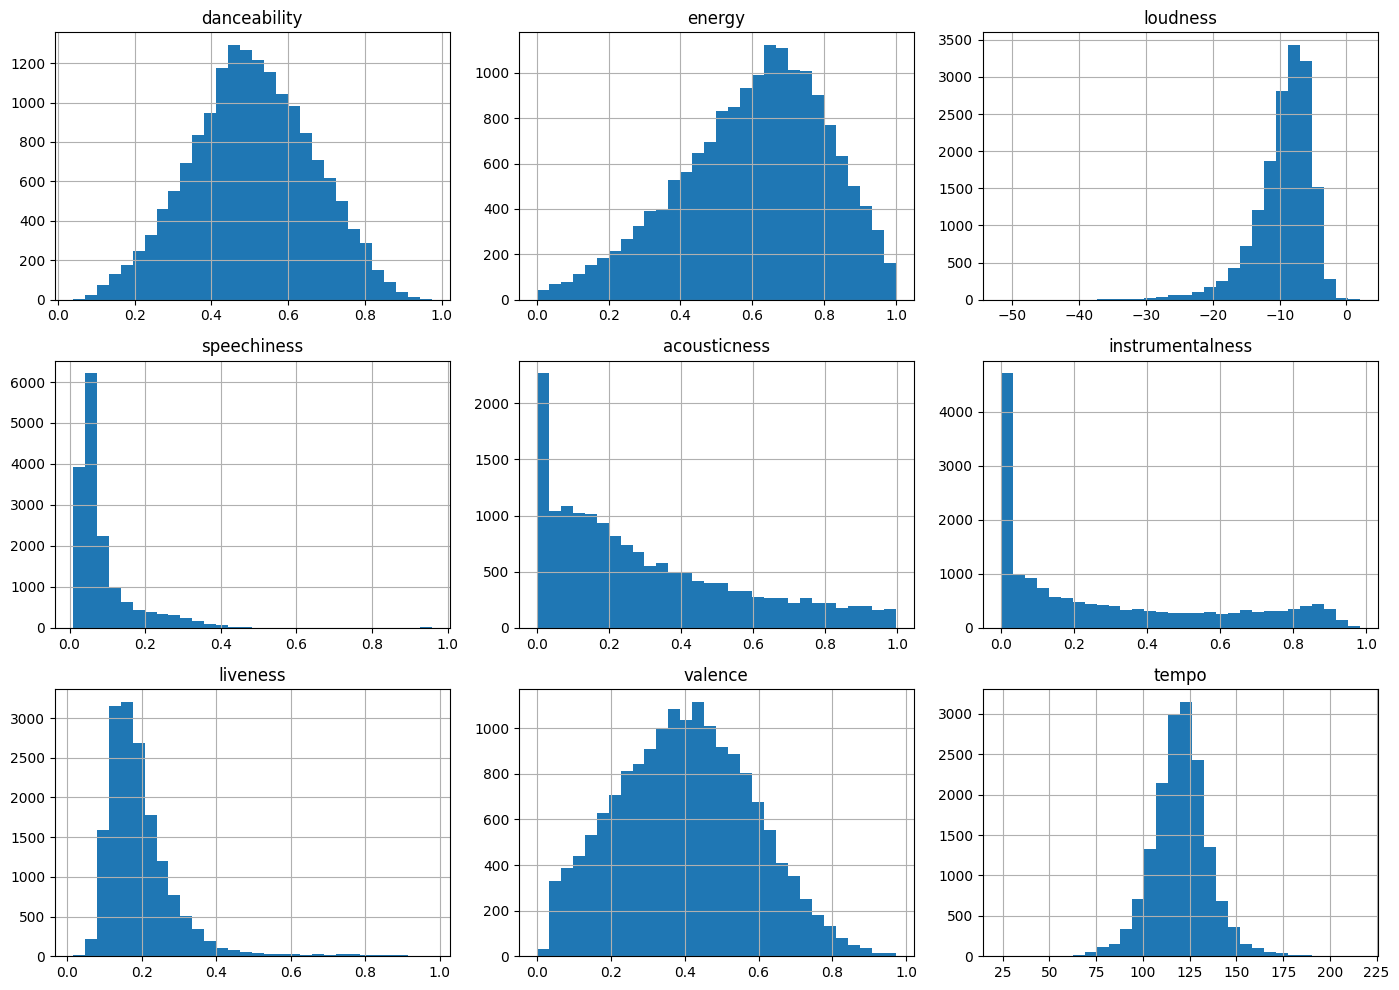

In [39]:
df[audio_features].hist(
    bins=30,
    figsize=(14, 10)
)

plt.tight_layout()
plt.show()

## 5.5 Correlations Between Spotify Audio Features

We calculate Pearson correlation coefficients between the nine Spotify audio features and visualize the results using a correlation heatmap.

The correlation coefficients range from −1 to 1, where positive values indicate that two features tend to increase together, negative values indicate that one tends to decrease as the other increases, and values near zero indicate little linear association.

This analysis helps identify which audio features tend to co-occur and which capture relatively distinct musical characteristics. These relationships provide useful context for understanding the structure of the audio data.

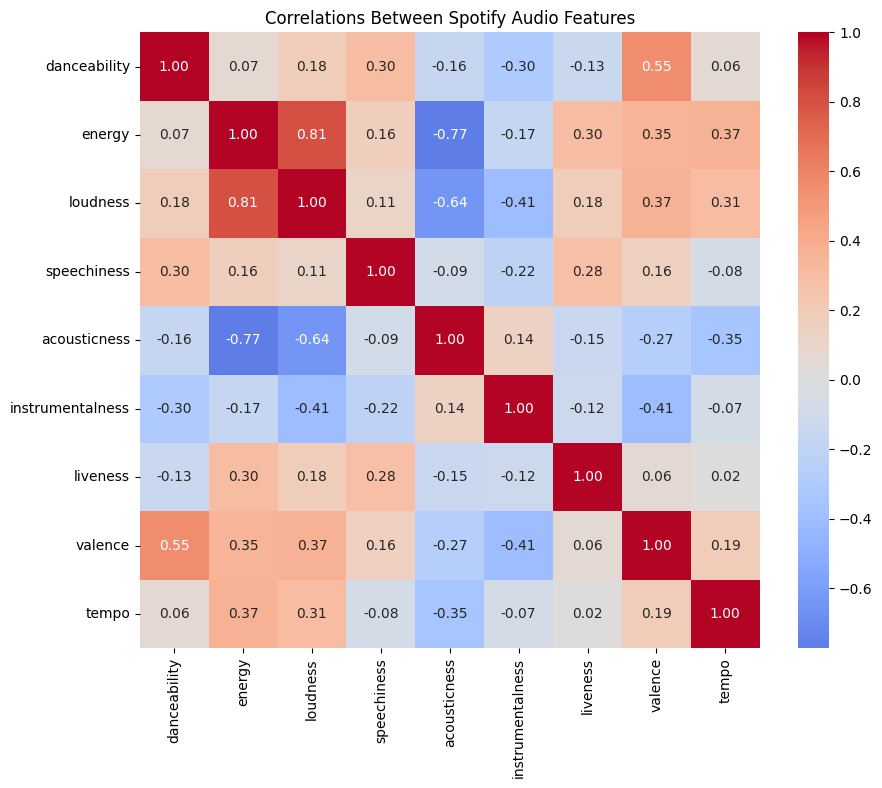

In [40]:
corr = df[audio_features].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    center=0,
    fmt=".2f"
)

plt.title("Correlations Between Spotify Audio Features")
plt.show()

In [41]:
df[audio_features + ["score"]].corr()["score"]

danceability       -0.075925
energy             -0.065797
loudness           -0.100361
speechiness         0.003280
acousticness        0.072401
instrumentalness    0.090231
liveness            0.003059
valence            -0.053766
tempo              -0.031608
score               1.000000
Name: score, dtype: float64

## 5.6 Review and Description Length Analysis

We examine the lengths of Pitchfork reviews and descriptions by calculating the number of words in each text.

We calculate summary statistics and visualize the distributions of review and description lengths to better understand the variation in textual content across the dataset.

Additionally, we calculate Pearson correlations between review length and Spotify audio features to explore whether the amount of written commentary is associated with particular musical characteristics.

In [42]:
df["review_length"] = (
    df["review"].str.split().str.len()
)

df["description_length"] = (
    df["description"].str.split().str.len()
)

display(df[["review_length", "description_length"]].describe())

,review_length,description_length
count,16222.000000,16222.000000
mean,663.753483,27.907286
std,252.007489,12.896688
min,11.000000,1.000000
25%,508.000000,20.000000
50%,613.000000,25.000000
75%,754.000000,34.000000
max,3591.000000,678.000000


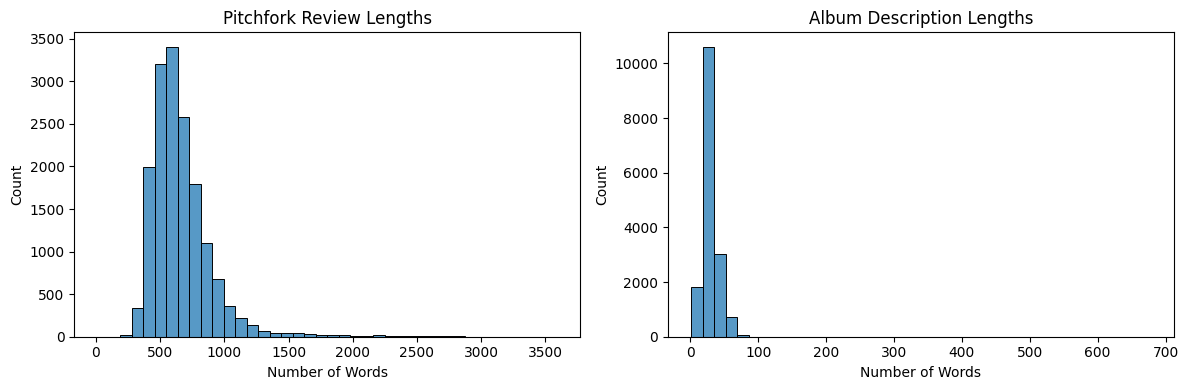

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["review_length"], bins=40, ax=axes[0])
axes[0].set_title("Pitchfork Review Lengths")
axes[0].set_xlabel("Number of Words")

sns.histplot(df["description_length"], bins=40, ax=axes[1])
axes[1].set_title("Album Description Lengths")
axes[1].set_xlabel("Number of Words")

plt.tight_layout()
plt.show()

In [44]:
df[audio_features + ["review_length"]].corr()["review_length"]

danceability        0.026288
energy              0.000714
loudness           -0.016577
speechiness         0.047813
acousticness       -0.010610
instrumentalness   -0.099644
liveness            0.051318
valence             0.054944
tempo              -0.020315
review_length       1.000000
Name: review_length, dtype: float64

## 5.7 Review Vocab Analysis

We examine the vocabulary used in Pitchfork reviews by identifying the most frequently occurring words across the dataset.

Using a bag-of-words representation, we calculate word frequencies while excluding common English stopwords. We then visualize the most frequent terms to identify recurring vocabulary in music criticism.

This preliminary textual analysis provides insight into the language used by reviewers and helps motivate more detailed analysis of how descriptive language relates to musical characteristics.

In [45]:
vectorizer = CountVectorizer(
    stop_words="english",
    max_features=30,
    min_df=5
)

X = vectorizer.fit_transform(
    df["review"].fillna("")
)

word_counts = pd.Series(
    X.sum(axis=0).A1,
    index=vectorizer.get_feature_names_out()
).sort_values(ascending=False)

display(word_counts)

like      61674
album     44239
music     31509
band      28963
songs     25306
song      23571
just      22603
sound     21304
record    18800
new       18627
time      18492
rock      18133
pop       16285
track     15577
guitar    15560
sounds    15216
way       14339
tracks    12776
work      11386
love      11364
best      11079
make      10993
years     10848
don       10324
little    10239
ve         9891
voice      9448
good       9344
long       8978
world      8510
dtype: int64

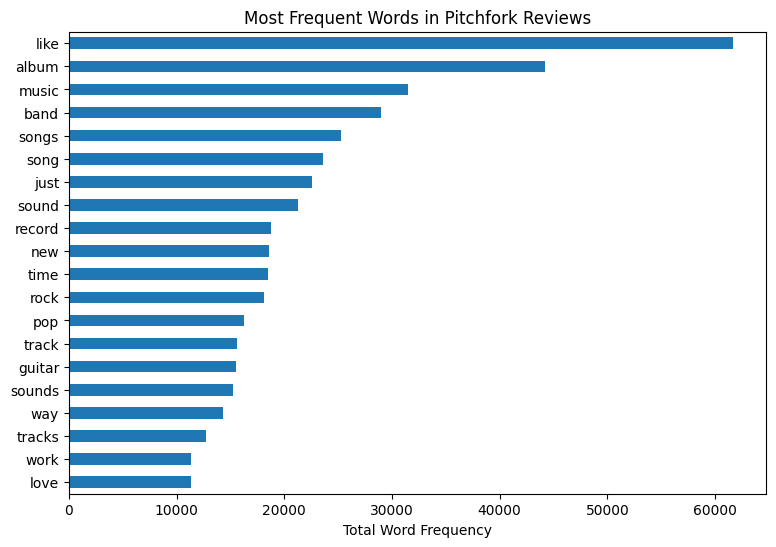

In [46]:
word_counts.head(20).sort_values().plot(
    kind="barh",
    figsize=(9, 6)
)

plt.title("Most Frequent Words in Pitchfork Reviews")
plt.xlabel("Total Word Frequency")
plt.show()

## 5.8 Genre-Level Comparisions

We examine how Spotify audio features and Pitchfork review scores vary across musical genres.

First, we calculate the number of observations within each genre and summarize their average audio characteristics. We then use boxplots to visualize differences in energy and review scores across the most frequently represented genres.

These comparisons allow us to identify genre-level patterns and consider how musical genre may influence relationships between audio characteristics and critical descriptions.

In [47]:
# Most common genres
print(df["genre"].value_counts().head(10))

# Mean audio features by genre
genre_stats = (
    df.groupby("genre")[audio_features]
    .mean()
    .round(3)
)

display(genre_stats)

genre
Rock            6116
Electronic      3206
Experimental    1458
Rap             1428
Pop/R&B         1086
Metal            688
Folk/Country     665
Jazz             247
Global           148
Name: count, dtype: int64


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
genre,,,,,,,,,
Electronic,0.546,0.618,-9.880,0.091,0.275,0.407,0.190,0.404,121.482
Experimental,0.430,0.547,-11.220,0.088,0.399,0.436,0.196,0.314,117.118
Folk/Country,0.485,0.427,-11.454,0.058,0.559,0.243,0.166,0.362,117.379
Global,0.600,0.629,-8.947,0.092,0.340,0.237,0.203,0.581,119.866
Jazz,0.473,0.531,-11.647,0.087,0.417,0.385,0.204,0.382,113.532
Metal,0.365,0.731,-7.986,0.090,0.142,0.439,0.221,0.282,122.786
Pop/R&B,0.572,0.586,-8.746,0.093,0.301,0.165,0.189,0.450,118.182
Rap,0.648,0.665,-7.550,0.221,0.215,0.077,0.228,0.487,117.414
Rock,0.479,0.604,-8.969,0.064,0.300,0.241,0.197,0.411,122.039


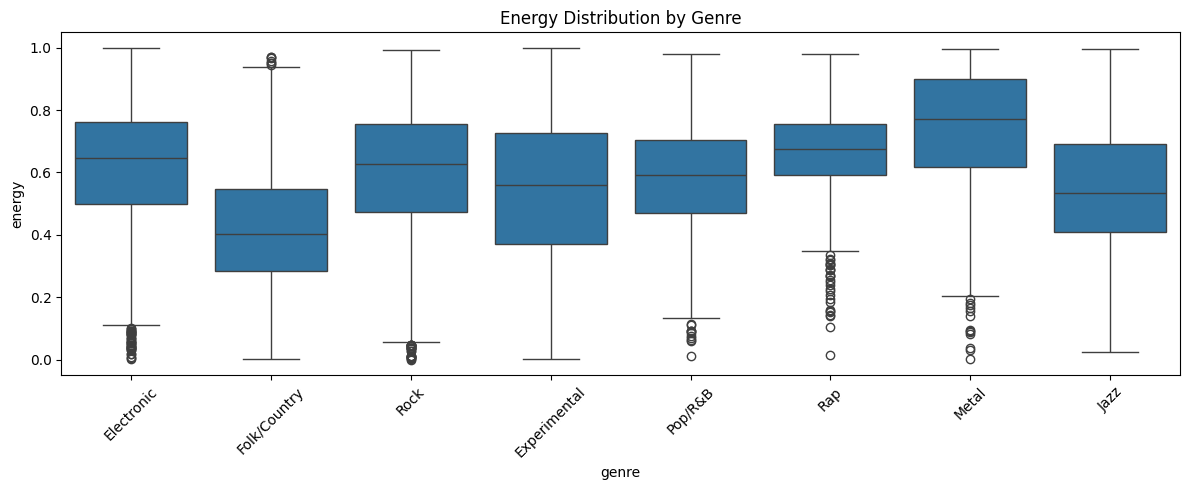

In [48]:
top_genres = df["genre"].value_counts().head(8).index

plt.figure(figsize=(12, 5))

sns.boxplot(
    data=df[df["genre"].isin(top_genres)],
    x="genre",
    y="energy"
)

plt.xticks(rotation=45)
plt.title("Energy Distribution by Genre")
plt.tight_layout()
plt.show()

In [49]:
genre_summary = (
    df.groupby("genre")
    .agg(
        album_count=("album", "count"),
        mean_energy=("energy", "mean"),
        mean_valence=("valence", "mean"),
        mean_acousticness=("acousticness", "mean"),
        mean_score=("score", "mean")
    )
    .sort_values("album_count", ascending=False)
)

display(genre_summary.head(10))

,album_count,mean_energy,mean_valence,mean_acousticness,mean_score
genre,,,,,
Rock,6116,0.603947,0.411025,0.300333,6.980232
Electronic,3206,0.617552,0.403730,0.275072,6.937867
Experimental,1458,0.546735,0.314205,0.399166,7.355350
Rap,1428,0.665072,0.487190,0.214657,6.978711
Pop/R&B,1086,0.586472,0.450059,0.300513,6.968600
Metal,688,0.730977,0.281955,0.142370,7.088953
Folk/Country,665,0.426572,0.362414,0.558621,7.210226
Jazz,247,0.531480,0.382473,0.417294,7.568016
Global,148,0.629004,0.581208,0.340451,7.406757


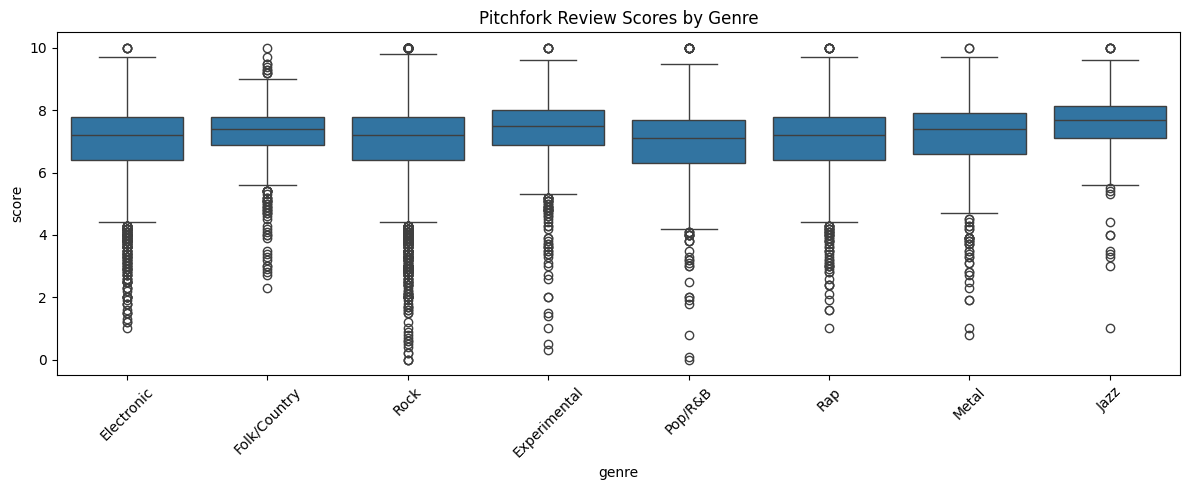

In [50]:
top_genres = df["genre"].value_counts().head(8).index

plt.figure(figsize=(12, 5))

sns.boxplot(
    data=df[df["genre"].isin(top_genres)],
    x="genre",
    y="score"
)

plt.xticks(rotation=45)
plt.title("Pitchfork Review Scores by Genre")
plt.tight_layout()
plt.show()

## 5.9 Audio Features and Review Scores


We examine the relationships between Spotify audio features and Pitchfork review scores to determine whether measurable musical characteristics are associated with critical ratings.

We calculate Pearson correlation coefficients between each audio feature and review score, then visualize the relationship between energy and score using a scatterplot.

This analysis provides an initial assessment of how numerical audio characteristics relate to critical evaluations, offering additional context for our subsequent investigation of review language.

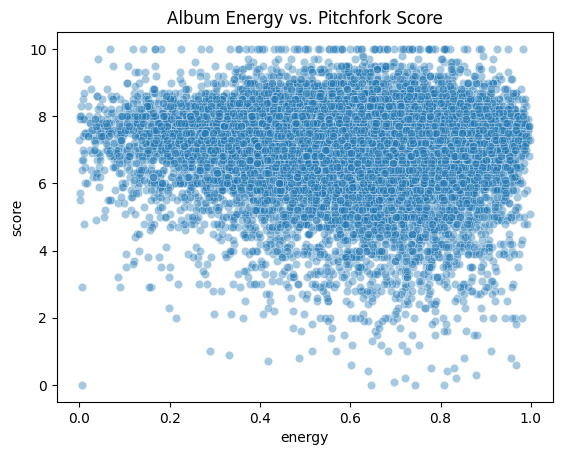

In [51]:
sns.scatterplot(
    data=df,
    x="energy",
    y="score",
    alpha=0.4
)


plt.title("Album Energy vs. Pitchfork Score")
plt.show()

# Preliminary Work

## 6. NLP baseline: review language and outcomes

The merge stage above writes `outputs/full_review.csv`: this contains the matched metadata, Pitchfork score, Spotify audio features, and review text. The following analysis uses TF-IDF unigram/bigram features and Ridge regression to predict the score and nine audio features. It uses a reproducible 80/20 held-out split and compares against a training-mean baseline. The vocabulary and target scaling are fit on training rows only. This is a simple language-modeling baseline; it does not replace the proposed word-by-word embedding analysis.

In [52]:
sys.path.insert(0, str(REPO_ROOT / "scripts"))
from preliminary_results import fit_tfidf_baseline

nlp_data = pd.read_csv(FULL_REVIEW_CSV)
metrics, top_terms, model_info = fit_tfidf_baseline(nlp_data)
print(
    f"Complete reviews: {model_info['complete_rows']:,}; "
    f"training: {model_info['train_rows']:,}; test: {model_info['test_rows']:,}; "
    f"training vocabulary: {model_info['vocabulary_size']:,} unigrams/bigrams"
)

metric_table = metrics.pivot(
    index="target", columns="model", values=["r2", "mae", "rmse"]
)
display(metric_table.round(3))

print("Largest positive/negative TF-IDF coefficients for selected outcomes:")
selected_terms = top_terms[
    top_terms["target"].isin(
        ["score", "danceability", "energy", "acousticness", "valence"]
    )
].groupby(["target", "direction"], sort=False).head(5)
display(selected_terms.reset_index(drop=True).round({"coefficient": 3}))


Complete reviews: 16,213; training: 12,970; test: 3,243; training vocabulary: 30,000 unigrams/bigrams


r2                                   mae                                  rmse                       
model            TF-IDF + Ridge Training-mean baseline TF-IDF + Ridge Training-mean baseline TF-IDF + Ridge Training-mean baseline
target                                                                                                                            
acousticness              0.270                 -0.000          0.177                  0.213          0.221                  0.258
danceability              0.290                 -0.000          0.106                  0.130          0.135                  0.160
energy                    0.263                 -0.000          0.135                  0.162          0.172                  0.200
instrumentalness          0.295                 -0.002          0.210                  0.263          0.256                  0.305
liveness                  0.085                 -0.001          0.064                  0.067          0.096                  0.100
loudness                  0.224                 -0.000          2.667                  3.129          3.717                  4.220
score                     0.311                 -0.001          0.758                  0.937          1.043                  1.256
speechiness               0.293                 -0.000          0.046                  0.059          0.073                  0.086
tempo                     0.082                 -0.001         10.683                 11.252         14.272                 14.907
valence                   0.244                 -0.000          0.129                  0.150          0.158                  0.182

Largest positive/negative TF-IDF coefficients for selected outcomes:


,target,direction,term,coefficient
0,score,positive,reissue,0.735
1,score,positive,also,0.673
2,score,positive,jazz,0.585
3,score,positive,perfect,0.565
4,score,positive,each,0.556
5,score,negative,unfortunately,-1.208
6,score,negative,problem,-1.151
7,score,negative,least,-1.136
8,score,negative,at least,-1.023
9,score,negative,worse,-0.969


### Interpreting the NLP baseline

Held-out R² indicates whether this bag-of-words model improves on predicting the training mean. TF-IDF ignores word order and context. Ridge coefficients show associations conditional on other correlated terms; they are not causal effects or true word embeddings. Since reviews can share authors or artists across a random split, grouped evaluation by reviewer, artist, or time is a useful next step. Any learned representation or other data-derived transformation must be fit on training folds only to avoid leakage.